# Домашняя работа 3. Логистическая регрессия.

### Оценивание и штрафы

Максимальная оценка — 10 баллов.

Не списывайте, иначе всем участникам обнулим :)

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Оценка: ...**

In [ ]:
print('Всем удачи!👒')

In [32]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)

## Логистическая регрессия

Модель логистической регрессии:
  $$
  \hat y = \sigma (Xw).
  $$
  Сигмоида меняется в пределах от 0 до 1 и имеет вид:
  $$
  \sigma(x) = \frac{1}{1+e^{-x}}.
  $$

  Функция потерь log-loss:
  $$
  L = -\frac{1}{\ell}\sum_{i = 1}^{\ell}(y_i\log(\hat y_i) + (1 - y_i)\log(1 - \hat y_i)),
  $$
  где $\ell$ - количество объектов.

## Градиентный спуск

Итеративный метод оптимизации, при котором вектор весов модели $\mathbf{w}^{(t+1)}$ на шаге $t+1$ может быть выражен как:
$$
\mathbf{w}^{(t+1)} = \mathbf{w}^{(t)} - \eta_t \nabla L(\mathbf{w}^{(t)}),
$$
где $\eta_t$ - шаг обучения.

## Часть 1. Логрег своими руками

**Задание 1 (8 баллов)**. Реализуйте логистическую регрессию, обучаемую с помощью:
- градиентного спуска **(4 балла)**

- стохастического градиентного спуска **(4 балла)**

Во всех пунктах необходимо соблюдать два условия:
- Циклы можно использовать только для итераций градиентного спуска;
- В качестве критерия останова необходимо использовать (одновременно):

    - проверку на евклидову норму разности весов на двух соседних итерациях (например, меньше некоторого малого числа порядка $10^{-6}$), задаваемого параметром `tolerance`;
    - достижение максимального числа итераций (например, 10000), задаваемого параметром `max_iter`.

Чтобы проследить, что оптимизационный процесс действительно сходится, добавим атрибут класса `loss_history`. В нём после вызова метода `fit` должны содержаться значения функции потерь для всех итераций градиентного спуска, начиная с нулевой.

Инициализировать веса можно случайным образом или нулевым вектором.

In [33]:
from sklearn.base import BaseEstimator
from scipy.special import expit

class LogReg(BaseEstimator):
    def __init__(self, gd_type: str = 'stochastic', tolerance: float = 1e-4,
                 max_iter: int = 1000, eta: float = 1e-2,
                 w0: np.array = None) -> None:
        """
        Args:
          gd_type: Type of gradient descent ('full' or 'stochastic').

          tolerance: Threshold for stopping gradient descent.

          max_iter: Maximum number of steps in gradient descent.

          eta: Learning rate.

          w0: Array of shape d (d — number of weights to optimize).
              Initial weights.
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.eta = eta
        self.w0 = w0
        self.w = None
        self.loss_history = None

    def fit(self, X: np.array, y: np.array) -> LogReg:
        """Fit the model on training data. Also, save value of loss after each iteration.

        Args:
          X: Training data.

          y: Target.

        Returns:
          self: Fitted classsifier.
        """
        X = np.asarray(X, dtype=float) #преобразуем матрицу признаков X в массив с вещественными числами
        y = np.asarray(y).ravel() #преобразуем правильные ответы у в одномерный массив, чтобы его форма соответствовала форме вектора предсказаний
        self.w = np.zeros(X.shape[1]) if self.w0 is None else np.asarray(self.w0, dtype=float).copy() #если начальные веса не переданы, создаём нулевой вектор длиной, равной числу признаков; иначе используем копию переданных весов
        self.loss_history = [self.calc_loss(X, y)] #вычисляем значение log-loss при начальных весах, сохраняем его в истории ошибок

        for _ in range(self.max_iter):
            if self.gd_type == 'full':
                gradient = self.calc_gradient(X, y) #вычисляем градиент по всем объектам
            else:
                i = np.random.randint(X.shape[0]) #cлучайно выбираем индекс строки матрицы X, то есть одного объекта обучающей выборки
                gradient = self.calc_gradient(X[i:i+1], y[i:i+1]) #вычисляем градиент только по одному выбранному объекту

            new_w = self.w - self.eta * gradient #обновляем веса по формуле градиентного спуска
            change = np.linalg.norm(new_w - self.w) #вычисляем евклидову длину вектора изменения весов за одну итерацию
            self.w = new_w #заменяем старые веса новыми
            self.loss_history.append(self.calc_loss(X, y))

            if change < self.tolerance: #проверяем, стало ли изменение весов меньше установленного порога, что является одним из критериев остановки
                break

        return self


    def predict_proba(self, X: np.array) -> np.array:
        """Calculate probability of positive and negative class for each observation.

        Args:
          X: Array of shape (n, d).
             Data.

        Returns:
             Array of shape (n, 2).
             Predicted probabilities.
        """
        if self.w is None: #проверяем, были ли обучены веса модели
            raise Exception('Not trained yet')
        p = expit(np.asarray(X) @ self.w) #cначала вычисляем линейную комбинацию признаков и весов, затем применяем сигмоиду и получаем вероятность класса 1 для каждого объекта
        return np.column_stack((1 - p, p)) #cоздаём матрицу из двух столбцов: первый содержит вероятности класса 0 (1-p), второй - вероятности класса 1 (p)


    def predict(self, X: np.array) -> np.array:
        """Predict class for each observation.

        Args:
          X: Array of shape (n, d).
             Data.

        Returns:
             Array of shape (n,).
             Predicted class labels.
        """
        if self.w is None: #проверяем, были ли обучены веса модели
            raise Exception('Not trained yet')
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)  #получаем вероятности класса 1 и сравниваем их с порогом 0.5: если вероятность не меньше 0.5, предсказываем 1, иначе 0

    def calc_gradient(self, X: np.array, y: np.array) -> np.array:
        """Calculate gradient of loss function after each iteration.

        Args:
          X: Array of shape (n, d), n can be equal to 1 if 'stochastic'.
          y: Array of shape (n,).

        Returns:
          Array of shape (d,).
          Gradient of loss function after current iteration.
        """
        p = expit(X @ self.w)  #вычисляем предсказанные вероятности
        return X.T @ (p - y) / X.shape[0]  #рассчитываем средний градиент по объектам

    def calc_loss(self, X: np.array, y: np.array) -> float:
        """Calculate value of loss function after each iteration.

        Args:
          X: Array of shape (n, d).
          y: Array of shape (n,).

        Returns:
          Value of loss function after current iteration.
        """
        z = X @ self.w
        return float(np.mean(np.logaddexp(0, z) - y * z))


Далее предполагается, что вы используете собственную реализацию логистической регрессии.
Если с написанием класса возникли проблемы, используйте реализацию sklearn, чтобы не терять баллы за остальные задания.

Сгенерируем синтетические данные.

In [34]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(
    n_samples=10000, n_features=10, n_informative=5, n_redundant=5,
    random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

**Задание 2 (1 балл).** Обучите логистическую регрессию на синтетических данных. Нарисуйте кривую обучения.

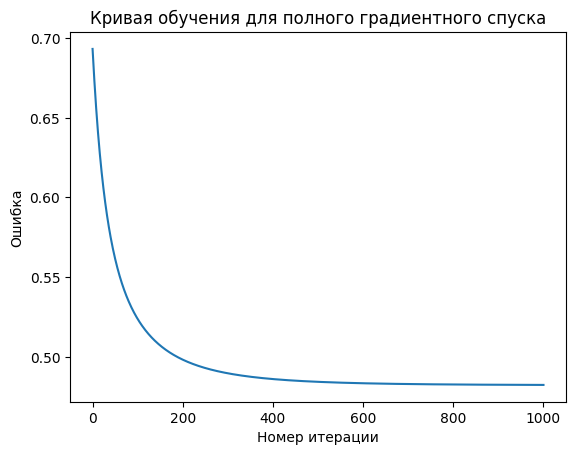

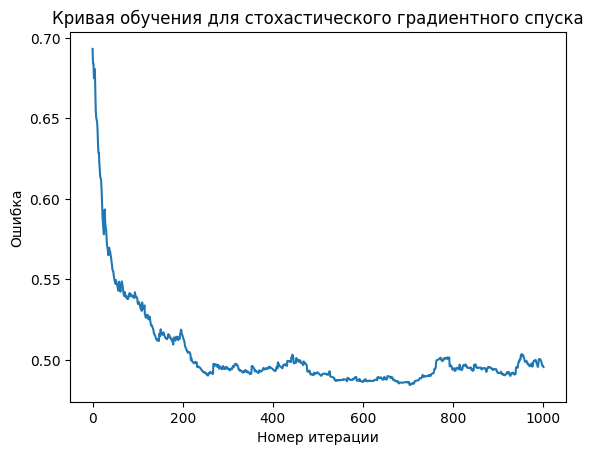

In [35]:
from sklearn.preprocessing import StandardScaler  #импортируем стандартизацию признаков

scaler = StandardScaler()
scaler.fit(X_train) #находим среднее и стандартное отклонение train
X_train_scaled = scaler.transform(X_train) #стандартизируем обучающие признаки
X_test_scaled = scaler.transform(X_test) #применяем параметры train к тестовым данным

X_train_model = np.column_stack((np.ones(X_train_scaled.shape[0]), X_train_scaled))  #добавляем столбец единиц к обучаемым данным, чтобы модель могла обучить свободный член w0
X_test_model = np.column_stack((np.ones(X_test_scaled.shape[0]), X_test_scaled))  #добавляем такой же столбец единиц к тестовым данным
model = LogReg(gd_type='full', eta=0.02, max_iter=1000, tolerance=1e-6)  #создаём модель с полным градиентным спуском и задаём параметры обучения
model.fit(X_train_model, y_train)  #обучаем модель

plt.plot(model.loss_history)
plt.xlabel('Номер итерации')
plt.ylabel('Ошибка')
plt.title('Кривая обучения для полного градиентного спуска')
plt.show()

np.random.seed(42) #фиксируем случайность, чтобы при повторных запусках получать одинаковые результаты
model_sgd = LogReg(gd_type='stochastic', eta=0.02, max_iter=1000, tolerance=1e-6) #создаём модель со стохастическим градиентным спуском и задаем параметры обучения
model_sgd.fit(X_train_model, y_train) #обучаем модель

plt.plot(model_sgd.loss_history)
plt.xlabel('Номер итерации')
plt.ylabel('Ошибка')
plt.title('Кривая обучения для стохастического градиентного спуска')
plt.show()

На тестовой части посчитайте ROC-AUC, PR-AUC. Постройте ROC и PR кривые.

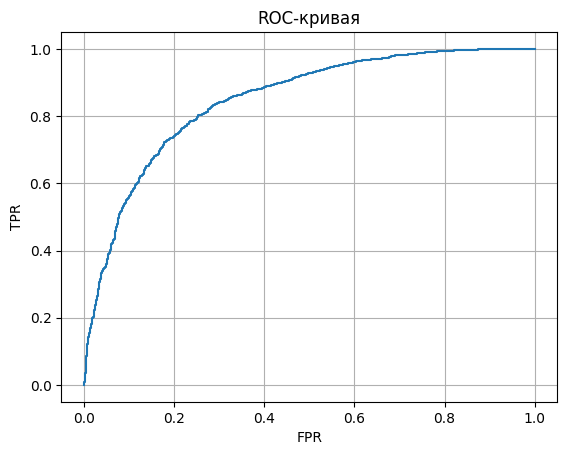

ROC-AUC: 0.8473310571891235


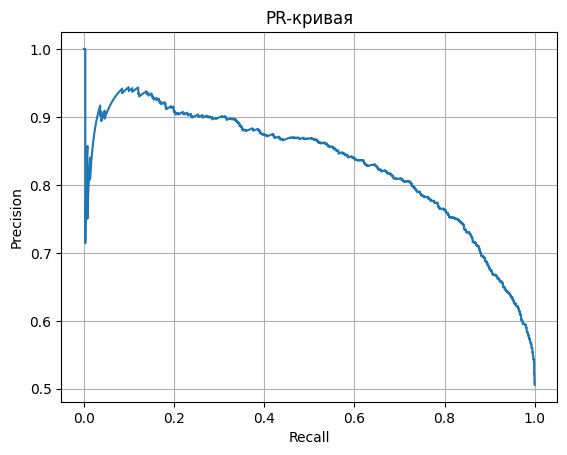

PR-AUC: 0.8309081239583291


In [36]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc  #импортируем функции для построения кривых и вычисления площадей

y_score = model.predict_proba(X_test_model)[:, 1]  #получаем вероятности класса 1 на тестовых данных

fpr, tpr, _ = roc_curve(y_test, y_score)  #рассчитываем FPR и TPR для разных порогов
roc_auc = auc(fpr, tpr)  #вычисляем площадь под ROC-кривой

plt.plot(fpr, tpr)
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC-кривая')
plt.grid()
plt.show()
print('ROC-AUC:', roc_auc)

precision, recall, _ = precision_recall_curve(y_test, y_score)  #рассчитываем Precision и Recall для разных порогов
pr_auc = auc(recall, precision)  #вычисляем площадь под PR-кривой

plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR-кривая')
plt.grid()
plt.show()
print('PR-AUC:', pr_auc)

**Задание 3 (1 балл).** Оцените ошибку ROC-AUC и PR-AUC вашей модели при помощи K-fold кросс валидации.  

In [37]:
from sklearn.model_selection import KFold  # Импортируем K-Fold.

kf = KFold(n_splits=5, shuffle=True, random_state=42)  #делим обучающую выборку на 5 случайных частей
roc_scores = []  #создаём список для значений ROC-AUC
pr_scores = []  #создаём список для значений PR-AUC

for train_idx, check_idx in kf.split(X_train):  #по очереди выделяем части для обучения и проверки
    scaler = StandardScaler()  #создаём новый стандартизатор для каждого разбиения
    X_tr = scaler.fit_transform(X_train[train_idx])  #стандартизируем обучающие данные
    X_check = scaler.transform(X_train[check_idx])  #стандартизируем проверочные данные по параметрам обучения

    X_tr = np.column_stack((np.ones(X_tr.shape[0]), X_tr))
    X_check = np.column_stack((np.ones(X_check.shape[0]), X_check))

    fold_model = LogReg(gd_type='full', eta=0.02, max_iter=1000, tolerance=1e-6)  #создаём новую модель
    fold_model.fit(X_tr, y_train[train_idx])  #обучаем модель на четырёх частях
    y_score = fold_model.predict_proba(X_check)[:, 1]  #предсказываем вероятности класса 1 на пятой части

    fpr, tpr, _ = roc_curve(y_train[check_idx], y_score)  #вычисляем значения FPR и TPR
    roc_scores.append(auc(fpr, tpr))  #считаем и сохраняем ROC-AUC

    precision, recall, _ = precision_recall_curve(y_train[check_idx], y_score)  #вычисляем Precision и Recall
    pr_scores.append(auc(recall, precision))  #считаем и сохраняем PR-AUC

print(f"ROC-AUC: {round(np.mean(roc_scores), 4)} +/- {round(np.std(roc_scores, ddof=1), 4)}")  #выводим средний ROC-AUC и его стандартное отклонение
print(f"PR-AUC: {round(np.mean(pr_scores), 4)} +/- {round(np.std(pr_scores, ddof=1), 4)}") #выводим средний PR-AUC и его стандартное отклонение


ROC-AUC: 0.8503 +/- 0.0134
PR-AUC: 0.8237 +/- 0.0145
